In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive/AML_Project'))

['notebooks', 'dataset', 'outputs', 'dashboard', 'report']


In [ ]:
dataset_path = "/content/drive/MyDrive/AML_Project/dataset"

print("Files in dataset folder:")
print(os.listdir(dataset_path))

Files in dataset folder:
['cities.csv', 'customers.csv', 'atms.csv', 'merchants.csv', 'transactions.csv', 'fraud_transactions_v1.csv', 'fraud_transactions_complete.csv']


In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/drive/MyDrive/AML_Project/dataset/fraud_transactions_complete.csv"

df = pd.read_csv(file_path)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df["amount"] = pd.to_numeric(
    df["amount"],
    errors="coerce"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (149994, 15)


/tmp/ipykernel_964/1126913081.py:6: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [ ]:
print(df.columns.tolist())
print()
print(df["fraud_type"].value_counts())

['transaction_id', 'sender', 'receiver', 'receiver_name', 'is_merchant', 'transaction_type', 'amount', 'timestamp', 'atm_id', 'city', 'state', 'latitude', 'longitude', 'fraud_type', 'pattern_id']

fraud_type
Normal                     148544
Mule                          300
Structuring                   300
Smurfing                      250
Layering                      200
Circular                      200
RapidGeographicMovement       200
Name: count, dtype: int64


In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTimestamp Range:")
print(df["timestamp"].min(), "→", df["timestamp"].max())

print("\nUnique Senders:", df["sender"].nunique())
print("Unique Receivers:", df["receiver"].nunique())

print("\nTransaction Types:")
print(df["transaction_type"].value_counts())

print("\nFraud Types:")
print(df["fraud_type"].value_counts())

Dataset Shape: (149994, 15)

Missing Values:
transaction_id           0
sender                   0
receiver                 0
receiver_name            0
is_merchant              0
transaction_type         0
amount                   0
timestamp                0
atm_id                1450
city                     0
state                    0
latitude                 0
longitude                0
fraud_type               0
pattern_id          148544
dtype: int64

Timestamp Range:
2026-01-01 07:00:03 → 2026-01-07 22:59:59

Unique Senders: 5000
Unique Receivers: 5353

Transaction Types:
transaction_type
Transfer        31794
UPI             24240
Shopping        21534
Bills           13921
ATM             12513
Card            11700
Healthcare       6683
Cash Deposit     6181
Food             4487
Fuel             4050
Investment       3268
Salary           2916
Recharge         2274
NEFT             2251
RTGS             2182
Name: count, dtype: int64

Fraud Types:
fraud_type
Normal        

In [ ]:
df = df.sort_values(
    ["sender", "timestamp"]
).reset_index(drop=True)

print("Transactions sorted successfully.")

display(
    df[
        [
            "transaction_id",
            "sender",
            "receiver",
            "transaction_type",
            "amount",
            "timestamp",
            "fraud_type",
            "pattern_id"
        ]
    ].head(15)
)

Transactions sorted successfully.


,transaction_id,sender,receiver,transaction_type,amount,timestamp,fraud_type,pattern_id
0,TX00000001,CUST00001,CUST00840,Card,8524.0,2026-01-01 14:08:47,Normal,NaN
1,TX00021204,CUST00001,MER00169,Fuel,3595.0,2026-01-02 13:31:46,Normal,NaN
2,TX00021206,CUST00001,MER00168,Fuel,1275.0,2026-01-02 18:10:34,Normal,NaN
3,TX00021205,CUST00001,CUST02662,UPI,3866.0,2026-01-02 22:02:10,Normal,NaN
4,TX00042517,CUST00001,MER00167,Fuel,921.0,2026-01-03 07:55:52,Normal,NaN
5,TX00042516,CUST00001,CUST01600,UPI,2073.0,2026-01-03 11:30:27,Normal,NaN
6,TX00063995,CUST00001,MER00027,Shopping,2136.0,2026-01-04 08:02:30,Normal,NaN
7,TX00084834,CUST00001,MER00169,Fuel,1583.0,2026-01-05 11:59:43,Normal,NaN
8,TX00084833,CUST00001,CUST03295,UPI,775.0,2026-01-05 15:33:14,Normal,NaN
9,TX00106302,CUST00001,MER00028,Shopping,9195.0,2026-01-06 13:11:20,Normal,NaN


In [ ]:
df["previous_timestamp"] = (
    df.groupby("sender")["timestamp"].shift(1)
)

df["time_gap_minutes"] = (
    (
        df["timestamp"] -
        df["previous_timestamp"]
    ).dt.total_seconds() / 60
)

df["time_gap_minutes"] = (
    df["time_gap_minutes"].fillna(0)
)

print("Time-gap calculation completed.")

display(
    df[
        [
            "sender",
            "timestamp",
            "transaction_type",
            "time_gap_minutes",
            "fraud_type"
        ]
    ].head(20)
)

Time-gap calculation completed.


,sender,timestamp,transaction_type,time_gap_minutes,fraud_type
0,CUST00001,2026-01-01 14:08:47,Card,0.000000,Normal
1,CUST00001,2026-01-02 13:31:46,Fuel,1402.983333,Normal
2,CUST00001,2026-01-02 18:10:34,Fuel,278.800000,Normal
3,CUST00001,2026-01-02 22:02:10,UPI,231.600000,Normal
4,CUST00001,2026-01-03 07:55:52,Fuel,593.700000,Normal
5,CUST00001,2026-01-03 11:30:27,UPI,214.583333,Normal
6,CUST00001,2026-01-04 08:02:30,Shopping,1232.050000,Normal
7,CUST00001,2026-01-05 11:59:43,Fuel,1677.216667,Normal
8,CUST00001,2026-01-05 15:33:14,UPI,213.516667,Normal
9,CUST00001,2026-01-06 13:11:20,Shopping,1298.100000,Normal


In [ ]:
df["sequence_item"] = (
    df["transaction_type"]
    .astype(str)
    .str.strip()
)

print("Sequence items created.")

print("\nUnique sequence items:")
print(df["sequence_item"].unique())

Sequence items created.

Unique sequence items:
['Card' 'Fuel' 'UPI' 'Shopping' 'Transfer' 'ATM' 'Bills' 'Healthcare'
 'Recharge' 'Food' 'NEFT' 'RTGS' 'Salary' 'Cash Deposit' 'Investment']


In [ ]:
sequences = (
    df.groupby("sender")["sequence_item"]
      .apply(list)
      .to_dict()
)

print("Number of customer sequences:", len(sequences))

print("\nSample sequences:")

for i, (customer, sequence) in enumerate(sequences.items()):

    print(f"\n{customer}:")
    print(sequence[:20])

    if i >= 4:
        break

Number of customer sequences: 5000

Sample sequences:

CUST00001:
['Card', 'Fuel', 'Fuel', 'UPI', 'Fuel', 'UPI', 'Shopping', 'Fuel', 'UPI', 'Shopping', 'Card', 'Fuel', 'Fuel', 'Card', 'Transfer']

CUST00002:
['UPI', 'Fuel', 'Card', 'Card', 'Fuel', 'UPI', 'Fuel', 'UPI', 'UPI', 'Fuel', 'UPI', 'Fuel', 'UPI']

CUST00003:
['ATM', 'UPI', 'ATM', 'UPI', 'ATM', 'Shopping', 'Bills', 'ATM', 'Bills', 'Bills', 'UPI', 'UPI', 'Bills', 'UPI', 'Shopping', 'Bills', 'ATM', 'UPI']

CUST00004:
['Healthcare', 'ATM', 'Healthcare', 'ATM', 'Bills', 'Bills', 'ATM', 'Bills', 'ATM', 'ATM', 'Healthcare', 'ATM', 'Bills', 'ATM', 'ATM', 'Bills', 'Bills', 'Bills', 'Bills', 'Healthcare']

CUST00005:
['Recharge', 'Shopping', 'Recharge', 'Food', 'UPI', 'Shopping', 'Shopping', 'Recharge', 'Recharge', 'UPI', 'Shopping', 'Food', 'UPI', 'Recharge', 'Shopping', 'Recharge', 'Recharge', 'Food', 'Recharge', 'Shopping']


In [ ]:
WINDOW_MINUTES = 60

df = df.sort_values(
    ["sender", "timestamp"]
).reset_index(drop=True)

df["time_diff"] = (
    df.groupby("sender")["timestamp"]
    .diff()
    .dt.total_seconds()
    / 60
)

# Start a new sequence whenever the gap exceeds 60 minutes
df["sequence_group"] = (
    (df["time_diff"].isna()) |
    (df["time_diff"] > WINDOW_MINUTES)
).groupby(df["sender"]).cumsum()

print("Time-windowed sequences created.")

Time-windowed sequences created.


In [ ]:

windowed_sequences = (
    df.groupby(
        ["sender", "sequence_group"]
    )["sequence_item"]
    .apply(list)
    .reset_index(name="sequence")
)

# Keep sequences with at least 2 transactions
windowed_sequences = windowed_sequences[
    windowed_sequences["sequence"].apply(len) >= 2
].reset_index(drop=True)

print(
    "Number of usable sequences:",
    len(windowed_sequences)
)

print("\nSample sequences:")

for i in range(min(10, len(windowed_sequences))):
    print(
        f"{windowed_sequences.loc[i, 'sender']} → "
        f"{windowed_sequences.loc[i, 'sequence']}"
    )

Number of usable sequences: 29389

Sample sequences:
CUST00002 → ['Fuel', 'Card']
CUST00003 → ['ATM', 'Shopping']
CUST00003 → ['ATM', 'Bills']
CUST00003 → ['UPI', 'Bills']
CUST00003 → ['UPI', 'Shopping']
CUST00003 → ['ATM', 'UPI']
CUST00004 → ['Healthcare', 'ATM', 'Healthcare', 'ATM']
CUST00004 → ['Bills', 'Bills']
CUST00004 → ['ATM', 'Bills']
CUST00004 → ['ATM', 'ATM']


In [ ]:

fraud_sequences = (
    df[df["fraud_type"] != "Normal"]
    .sort_values(["pattern_id", "timestamp"])
    .groupby("pattern_id")["sequence_item"]
    .apply(list)
)

print("Number of planted fraud patterns found:",
      len(fraud_sequences))

print("\nSample planted patterns:")

for pattern_id, sequence in list(fraud_sequences.items())[:10]:
    print(pattern_id, "→", sequence)

Number of planted fraud patterns found: 300

Sample planted patterns:
CIRC_001 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_002 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_003 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_004 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_005 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_006 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_007 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_008 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_009 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']
CIRC_010 → ['Transfer', 'Transfer', 'Transfer', 'Transfer']


In [ ]:
!pip install prefixspan -q

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done


In [ ]:
from prefixspan import PrefixSpan

print("PrefixSpan imported successfully!")

PrefixSpan imported successfully!


In [ ]:
prefixspan_sequences = (
    windowed_sequences["sequence"]
    .tolist()
)

print("Sequences prepared:", len(prefixspan_sequences))

print("\nFirst 5 sequences:")

for sequence in prefixspan_sequences[:5]:
    print(sequence)

Sequences prepared: 29389

First 5 sequences:
['Fuel', 'Card']
['ATM', 'Shopping']
['ATM', 'Bills']
['UPI', 'Bills']
['UPI', 'Shopping']


In [ ]:
# Cell 16 — Run PrefixSpan

MIN_SUPPORT = max(
    10,
    int(len(prefixspan_sequences) * 0.01)
)

print("Minimum support:", MIN_SUPPORT)

ps = PrefixSpan(prefixspan_sequences)

patterns = ps.frequent(
    MIN_SUPPORT
)

print("\nNumber of frequent patterns found:", len(patterns))

Minimum support: 293

Number of frequent patterns found: 75


In [ ]:
# Cell 17 — Display frequent sequential patterns

patterns_sorted = sorted(
    patterns,
    key=lambda x: x[0],
    reverse=True
)

print("Top 30 PrefixSpan patterns:\n")

for support, pattern in patterns_sorted[:30]:

    print(
        f"Support: {support:5d} | "
        f"Pattern: {' → '.join(pattern)}"
    )

Top 30 PrefixSpan patterns:

Support: 11001 | Pattern: Transfer
Support:  9260 | Pattern: UPI
Support:  8684 | Pattern: Shopping
Support:  5079 | Pattern: Bills
Support:  4680 | Pattern: ATM
Support:  4653 | Pattern: Card
Support:  3765 | Pattern: Transfer → Transfer
Support:  2644 | Pattern: Healthcare
Support:  2437 | Pattern: Cash Deposit
Support:  2402 | Pattern: UPI → UPI
Support:  1750 | Pattern: Food
Support:  1734 | Pattern: Shopping → Shopping
Support:  1724 | Pattern: Shopping → UPI
Support:  1723 | Pattern: UPI → Shopping
Support:  1600 | Pattern: Fuel
Support:  1541 | Pattern: Transfer → Shopping
Support:  1522 | Pattern: Bills → Bills
Support:  1481 | Pattern: Shopping → Transfer
Support:  1411 | Pattern: ATM → Bills
Support:  1376 | Pattern: Investment
Support:  1357 | Pattern: Bills → ATM
Support:  1326 | Pattern: ATM → ATM
Support:  1285 | Pattern: Card → Transfer
Support:  1284 | Pattern: Transfer → Card
Support:  1191 | Pattern: Salary
Support:  1124 | Pattern: Transf

In [ ]:
prefixspan_sequences = windowed_sequences["sequence"].tolist()

print("Sequences prepared:", len(prefixspan_sequences))

for sequence in prefixspan_sequences[:5]:
    print(sequence)

Sequences prepared: 29389
['Fuel', 'Card']
['ATM', 'Shopping']
['ATM', 'Bills']
['UPI', 'Bills']
['UPI', 'Shopping']


In [ ]:
MIN_SUPPORT = max(
    10,
    int(len(prefixspan_sequences) * 0.01)
)

print("Minimum support:", MIN_SUPPORT)

ps = PrefixSpan(prefixspan_sequences)

patterns = ps.frequent(MIN_SUPPORT)

print("Number of frequent patterns found:", len(patterns))

Minimum support: 293
Number of frequent patterns found: 75


In [ ]:
# Cell 17 — Display PrefixSpan Results

patterns_sorted = sorted(
    patterns,
    key=lambda x: x[0],
    reverse=True
)

print("Total frequent patterns:", len(patterns_sorted))
print("\nAll discovered patterns:\n")

for support, pattern in patterns_sorted:
    print(
        f"Support: {support:5d} | "
        f"Pattern: {' → '.join(pattern)}"
    )

Total frequent patterns: 75

All discovered patterns:

Support: 11001 | Pattern: Transfer
Support:  9260 | Pattern: UPI
Support:  8684 | Pattern: Shopping
Support:  5079 | Pattern: Bills
Support:  4680 | Pattern: ATM
Support:  4653 | Pattern: Card
Support:  3765 | Pattern: Transfer → Transfer
Support:  2644 | Pattern: Healthcare
Support:  2437 | Pattern: Cash Deposit
Support:  2402 | Pattern: UPI → UPI
Support:  1750 | Pattern: Food
Support:  1734 | Pattern: Shopping → Shopping
Support:  1724 | Pattern: Shopping → UPI
Support:  1723 | Pattern: UPI → Shopping
Support:  1600 | Pattern: Fuel
Support:  1541 | Pattern: Transfer → Shopping
Support:  1522 | Pattern: Bills → Bills
Support:  1481 | Pattern: Shopping → Transfer
Support:  1411 | Pattern: ATM → Bills
Support:  1376 | Pattern: Investment
Support:  1357 | Pattern: Bills → ATM
Support:  1326 | Pattern: ATM → ATM
Support:  1285 | Pattern: Card → Transfer
Support:  1284 | Pattern: Transfer → Card
Support:  1191 | Pattern: Salary
Suppor

In [ ]:
# Cell 18 — PrefixSpan Results Table

prefixspan_results = pd.DataFrame(
    [
        {
            "support": support,
            "pattern": " → ".join(pattern),
            "length": len(pattern)
        }
        for support, pattern in patterns_sorted
    ]
)

display(prefixspan_results.head(20))

,support,pattern,length
0,11001,Transfer,1
1,9260,UPI,1
2,8684,Shopping,1
3,5079,Bills,1
4,4680,ATM,1
5,4653,Card,1
6,3765,Transfer → Transfer,2
7,2644,Healthcare,1
8,2437,Cash Deposit,1
9,2402,UPI → UPI,2


In [ ]:
# Cell 19 — Pattern Length Distribution

print(
    prefixspan_results["length"]
    .value_counts()
    .sort_index()
)

length
1    15
2    58
3     2
Name: count, dtype: int64


In [ ]:
# Cell 20 — Clean PrefixSpan Summary

prefixspan_results = pd.DataFrame(
    [
        {
            "support": support,
            "pattern": " → ".join(pattern),
            "length": len(pattern)
        }
        for support, pattern in patterns_sorted
    ]
)

print("Total patterns:", len(prefixspan_results))

print("\nPattern length distribution:")
print(
    prefixspan_results["length"]
    .value_counts()
    .sort_index()
)

print("\nTop 20 patterns:")

display(
    prefixspan_results.head(20)
)

Total patterns: 75

Pattern length distribution:
length
1    15
2    58
3     2
Name: count, dtype: int64

Top 20 patterns:


,support,pattern,length
0,11001,Transfer,1
1,9260,UPI,1
2,8684,Shopping,1
3,5079,Bills,1
4,4680,ATM,1
5,4653,Card,1
6,3765,Transfer → Transfer,2
7,2644,Healthcare,1
8,2437,Cash Deposit,1
9,2402,UPI → UPI,2


In [ ]:
# Cell 21 — Map planted fraud patterns to their transaction sequences

fraud_pattern_sequences = (
    df[df["fraud_type"] != "Normal"]
    .sort_values(["pattern_id", "timestamp"])
    .groupby("pattern_id")
    .agg(
        fraud_type=("fraud_type", "first"),
        sequence=("sequence_item", list)
    )
    .reset_index()
)

print(
    "Total planted patterns:",
    len(fraud_pattern_sequences)
)

display(
    fraud_pattern_sequences.head(10)
)

Total planted patterns: 300


,pattern_id,fraud_type,sequence
0,CIRC_001,Circular,"[Transfer, Transfer, Transfer, Transfer]"
1,CIRC_002,Circular,"[Transfer, Transfer, Transfer, Transfer]"
2,CIRC_003,Circular,"[Transfer, Transfer, Transfer, Transfer]"
3,CIRC_004,Circular,"[Transfer, Transfer, Transfer, Transfer]"
4,CIRC_005,Circular,"[Transfer, Transfer, Transfer, Transfer]"
5,CIRC_006,Circular,"[Transfer, Transfer, Transfer, Transfer]"
6,CIRC_007,Circular,"[Transfer, Transfer, Transfer, Transfer]"
7,CIRC_008,Circular,"[Transfer, Transfer, Transfer, Transfer]"
8,CIRC_009,Circular,"[Transfer, Transfer, Transfer, Transfer]"
9,CIRC_010,Circular,"[Transfer, Transfer, Transfer, Transfer]"


In [ ]:
# Cell 22 — Match PrefixSpan patterns against planted fraud sequences

def contains_subsequence(sequence, pattern):
    """
    Check whether pattern occurs as an ordered subsequence
    inside sequence.
    """

    if len(pattern) > len(sequence):
        return False

    j = 0

    for item in sequence:

        if item == pattern[j]:
            j += 1

            if j == len(pattern):
                return True

    return False


matching_results = []

for _, row in fraud_pattern_sequences.iterrows():

    fraud_sequence = row["sequence"]

    for _, p in prefixspan_results.iterrows():

        pattern = p["pattern"].split(" → ")

        if contains_subsequence(
            fraud_sequence,
            pattern
        ):

            matching_results.append({

                "pattern_id":
                    row["pattern_id"],

                "fraud_type":
                    row["fraud_type"],

                "fraud_sequence":
                    " → ".join(fraud_sequence),

                "discovered_pattern":
                    p["pattern"],

                "support":
                    p["support"],

                "pattern_length":
                    p["length"]
            })


prefixspan_fraud_matches = pd.DataFrame(
    matching_results
)

print(
    "Fraud-pattern associations found:",
    len(prefixspan_fraud_matches)
)

display(
    prefixspan_fraud_matches.head(20)
)

Fraud-pattern associations found: 900


,pattern_id,fraud_type,fraud_sequence,discovered_pattern,support,pattern_length
0,CIRC_001,Circular,Transfer → Transfer → Transfer → Transfer,Transfer,11001,1
1,CIRC_001,Circular,Transfer → Transfer → Transfer → Transfer,Transfer → Transfer,3765,2
2,CIRC_001,Circular,Transfer → Transfer → Transfer → Transfer,Transfer → Transfer → Transfer,753,3
3,CIRC_002,Circular,Transfer → Transfer → Transfer → Transfer,Transfer,11001,1
4,CIRC_002,Circular,Transfer → Transfer → Transfer → Transfer,Transfer → Transfer,3765,2
5,CIRC_002,Circular,Transfer → Transfer → Transfer → Transfer,Transfer → Transfer → Transfer,753,3
6,CIRC_003,Circular,Transfer → Transfer → Transfer → Transfer,Transfer,11001,1
7,CIRC_003,Circular,Transfer → Transfer → Transfer → Transfer,Transfer → Transfer,3765,2
8,CIRC_003,Circular,Transfer → Transfer → Transfer → Transfer,Transfer → Transfer → Transfer,753,3
9,CIRC_004,Circular,Transfer → Transfer → Transfer → Transfer,Transfer,11001,1


In [ ]:
# Cell 23 — Exact sequence support

def exact_sequence_support(sequence, target_pattern):
    """
    Count how many sequences exactly match target_pattern.
    """
    return sum(
        seq == target_pattern
        for seq in sequence
    )


# Count exact occurrences of each planted pattern
exact_results = []

for _, row in fraud_pattern_sequences.iterrows():

    target = row["sequence"]

    exact_count = exact_sequence_support(
        fraud_pattern_sequences["sequence"],
        target
    )

    exact_results.append({
        "pattern_id": row["pattern_id"],
        "fraud_type": row["fraud_type"],
        "sequence": " → ".join(target),
        "exact_count_in_fraud_patterns": exact_count
    })

exact_results_df = pd.DataFrame(exact_results)

display(exact_results_df.head(20))

,pattern_id,fraud_type,sequence,exact_count_in_fraud_patterns
0,CIRC_001,Circular,Transfer → Transfer → Transfer → Transfer,150
1,CIRC_002,Circular,Transfer → Transfer → Transfer → Transfer,150
2,CIRC_003,Circular,Transfer → Transfer → Transfer → Transfer,150
3,CIRC_004,Circular,Transfer → Transfer → Transfer → Transfer,150
4,CIRC_005,Circular,Transfer → Transfer → Transfer → Transfer,150
5,CIRC_006,Circular,Transfer → Transfer → Transfer → Transfer,150
6,CIRC_007,Circular,Transfer → Transfer → Transfer → Transfer,150
7,CIRC_008,Circular,Transfer → Transfer → Transfer → Transfer,150
8,CIRC_009,Circular,Transfer → Transfer → Transfer → Transfer,150
9,CIRC_010,Circular,Transfer → Transfer → Transfer → Transfer,150


In [ ]:
# Cell 24 — Create Amount Categories

def amount_category(amount):

    if amount < 10000:
        return "LOW"

    elif amount < 50000:
        return "MEDIUM"

    elif amount < 100000:
        return "HIGH"

    else:
        return "VERY_HIGH"


df["amount_category"] = (
    df["amount"]
    .apply(amount_category)
)

df["rich_sequence_item"] = (
    df["transaction_type"].astype(str)
    + "_"
    + df["amount_category"]
)

display(
    df[
        [
            "transaction_type",
            "amount",
            "amount_category",
            "rich_sequence_item",
            "fraud_type"
        ]
    ].head(20)
)

,transaction_type,amount,amount_category,rich_sequence_item,fraud_type
0,Card,8524.0,LOW,Card_LOW,Normal
1,Fuel,3595.0,LOW,Fuel_LOW,Normal
2,Fuel,1275.0,LOW,Fuel_LOW,Normal
3,UPI,3866.0,LOW,UPI_LOW,Normal
4,Fuel,921.0,LOW,Fuel_LOW,Normal
5,UPI,2073.0,LOW,UPI_LOW,Normal
6,Shopping,2136.0,LOW,Shopping_LOW,Normal
7,Fuel,1583.0,LOW,Fuel_LOW,Normal
8,UPI,775.0,LOW,UPI_LOW,Normal
9,Shopping,9195.0,LOW,Shopping_LOW,Normal


In [ ]:
# Cell 25 — Build Rich Sequences

rich_windowed_sequences = (
    df.groupby(
        ["sender", "sequence_group"]
    )["rich_sequence_item"]
    .apply(list)
    .reset_index(name="sequence")
)

rich_windowed_sequences = rich_windowed_sequences[
    rich_windowed_sequences["sequence"].apply(len) >= 2
].reset_index(drop=True)

print(
    "Rich sequences:",
    len(rich_windowed_sequences)
)

print("\nSample rich sequences:")

for sequence in rich_windowed_sequences["sequence"].head(10):
    print(sequence)

Rich sequences: 29389

Sample rich sequences:
['Fuel_LOW', 'Card_MEDIUM']
['ATM_LOW', 'Shopping_LOW']
['ATM_LOW', 'Bills_LOW']
['UPI_LOW', 'Bills_LOW']
['UPI_LOW', 'Shopping_LOW']
['ATM_LOW', 'UPI_LOW']
['Healthcare_MEDIUM', 'ATM_LOW', 'Healthcare_LOW', 'ATM_LOW']
['Bills_LOW', 'Bills_LOW']
['ATM_LOW', 'Bills_LOW']
['ATM_LOW', 'ATM_LOW']


In [ ]:
# Cell 26 — PrefixSpan on Rich Sequences

rich_sequences = (
    rich_windowed_sequences["sequence"]
    .tolist()
)

print("Rich sequences:", len(rich_sequences))

# Use 1% minimum support again
RICH_MIN_SUPPORT = max(
    10,
    int(len(rich_sequences) * 0.01)
)

print("Minimum support:", RICH_MIN_SUPPORT)

ps_rich = PrefixSpan(rich_sequences)

rich_patterns = ps_rich.frequent(
    RICH_MIN_SUPPORT
)

print(
    "Number of rich frequent patterns:",
    len(rich_patterns)
)

Rich sequences: 29389
Minimum support: 293
Number of rich frequent patterns: 70


In [ ]:
# Cell 27 — Rich PrefixSpan Results

rich_patterns_sorted = sorted(
    rich_patterns,
    key=lambda x: x[0],
    reverse=True
)

print("Top 40 rich sequential patterns:\n")

for support, pattern in rich_patterns_sorted[:40]:

    print(
        f"Support: {support:5d} | "
        f"Pattern: {' → '.join(pattern)}"
    )

Top 40 rich sequential patterns:

Support:  9393 | Pattern: Transfer_MEDIUM
Support:  9260 | Pattern: UPI_LOW
Support:  6052 | Pattern: Shopping_LOW
Support:  5079 | Pattern: Bills_LOW
Support:  4680 | Pattern: ATM_LOW
Support:  3411 | Pattern: Shopping_MEDIUM
Support:  2740 | Pattern: Transfer_LOW
Support:  2672 | Pattern: Card_MEDIUM
Support:  2600 | Pattern: Transfer_MEDIUM → Transfer_MEDIUM
Support:  2564 | Pattern: Card_LOW
Support:  2402 | Pattern: UPI_LOW → UPI_LOW
Support:  1808 | Pattern: Healthcare_MEDIUM
Support:  1750 | Pattern: Food_LOW
Support:  1600 | Pattern: Fuel_LOW
Support:  1522 | Pattern: Bills_LOW → Bills_LOW
Support:  1433 | Pattern: Cash Deposit_HIGH
Support:  1411 | Pattern: ATM_LOW → Bills_LOW
Support:  1357 | Pattern: Bills_LOW → ATM_LOW
Support:  1326 | Pattern: ATM_LOW → ATM_LOW
Support:  1177 | Pattern: UPI_LOW → Shopping_LOW
Support:  1172 | Pattern: Shopping_LOW → UPI_LOW
Support:  1160 | Pattern: Cash Deposit_MEDIUM
Support:  1117 | Pattern: Healthcare_

In [ ]:
# Cell 28 — Save Rich PrefixSpan Results

rich_prefixspan_results = pd.DataFrame(
    [
        {
            "support": support,
            "pattern": " → ".join(pattern),
            "length": len(pattern)
        }
        for support, pattern in rich_patterns_sorted
    ]
)

print(
    "Total rich patterns:",
    len(rich_prefixspan_results)
)

display(
    rich_prefixspan_results.head(20)
)

Total rich patterns: 70


,support,pattern,length
0,9393,Transfer_MEDIUM,1
1,9260,UPI_LOW,1
2,6052,Shopping_LOW,1
3,5079,Bills_LOW,1
4,4680,ATM_LOW,1
5,3411,Shopping_MEDIUM,1
6,2740,Transfer_LOW,1
7,2672,Card_MEDIUM,1
8,2600,Transfer_MEDIUM → Transfer_MEDIUM,2
9,2564,Card_LOW,1


In [ ]:
# Cell 29 — Compare PrefixSpan Versions

print("BASIC PREFIXSPAN")
print("----------------")
print(
    "Number of patterns:",
    len(prefixspan_results)
)

print(
    "Longest pattern:",
    prefixspan_results["length"].max()
)

print("\nRICH PREFIXSPAN")
print("----------------")
print(
    "Number of patterns:",
    len(rich_prefixspan_results)
)

print(
    "Longest pattern:",
    rich_prefixspan_results["length"].max()
)

BASIC PREFIXSPAN
----------------
Number of patterns: 75
Longest pattern: 3

RICH PREFIXSPAN
----------------
Number of patterns: 70
Longest pattern: 3


In [ ]:
!pip install gsppy -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.8/61.8 kB 4.9 MB/s eta 0:00:00


In [ ]:
from gsppy.gsp import GSP

print("GSP imported successfully!")

GSP imported successfully!


In [ ]:
# Cell 32 — Prepare sequences for GSP

gsp_sequences = [
    sequence
    for sequence in windowed_sequences["sequence"].tolist()
    if len(sequence) >= 2
]

print("Sequences for GSP:", len(gsp_sequences))

print("\nSample:")
for sequence in gsp_sequences[:5]:
    print(sequence)

Sequences for GSP: 29389

Sample:
['Fuel', 'Card']
['ATM', 'Shopping']
['ATM', 'Bills']
['UPI', 'Bills']
['UPI', 'Shopping']


In [ ]:
# Cell 33A — Check installed GSP API

import inspect
from gsppy.gsp import GSP

print("GSP constructor:")
print(inspect.signature(GSP))

print("\nGSP methods:")
print([m for m in dir(GSP) if not m.startswith("_")])

GSP constructor:
(raw_transactions: "Union[List[List[str]], List[List[Tuple[str, float]]], List[List[List[str]]], List[List[List[Tuple[str, float]]]], 'pl.DataFrame', 'pl.LazyFrame', 'pd.DataFrame']", mingap: 'Optional[float]' = None, maxgap: 'Optional[float]' = None, maxspan: 'Optional[float]' = None, verbose: 'bool' = False, pruning_strategy: 'Optional[PruningStrategy]' = None, transaction_col: 'Optional[str]' = None, item_col: 'Optional[str]' = None, timestamp_col: 'Optional[str]' = None, sequence_col: 'Optional[str]' = None)

GSP methods:
['search']


In [ ]:
# Cell 33B — Check package version

import gsppy

print("gsppy version:", getattr(gsppy, "__version__", "version not exposed"))

gsppy version: 5.3.0


In [ ]:
# Cell 33 — Initialize GSP

from gsppy.gsp import GSP

gsp = GSP(
    gsp_sequences,
    verbose=False
)

print("GSP initialized successfully!")

GSP initialized successfully!


In [ ]:
# Cell 34 — Run GSP

GSP_MIN_SUPPORT = 0.01

gsp_result = gsp.search(
    min_support=GSP_MIN_SUPPORT,
    max_k=4
)

print("GSP execution completed!")
print("Number of result levels:", len(gsp_result))

for i, level in enumerate(gsp_result):

    print(
        f"\nLevel {i + 1}: "
        f"{len(level)} patterns"
    )

GSP execution completed!
Number of result levels: 2

Level 1: 15 patterns

Level 2: 47 patterns


In [ ]:
# Cell 35 — Display GSP Results

gsp_patterns = []

for level_number, level in enumerate(gsp_result, start=1):

    for pattern, support in level.items():

        gsp_patterns.append({
            "pattern": " → ".join(pattern),
            "support": support,
            "length": len(pattern),
            "level": level_number
        })

gsp_results_df = pd.DataFrame(gsp_patterns)

gsp_results_df = gsp_results_df.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

print(
    "Total GSP patterns:",
    len(gsp_results_df)
)

display(
    gsp_results_df.head(40)
)

Total GSP patterns: 62


,pattern,support,length,level
0,Transfer,11001,1,1
1,UPI,9260,1,1
2,Shopping,8684,1,1
3,Bills,5079,1,1
4,ATM,4680,1,1
5,Card,4653,1,1
6,Healthcare,2644,1,1
7,Cash Deposit,2437,1,1
8,Food,1750,1,1
9,Shopping → UPI,1724,2,2


In [ ]:
# Cell 36 — Algorithm Comparison

print("========== ALGORITHM COMPARISON ==========")

print(
    "\nPrefixSpan patterns:",
    len(prefixspan_results)
)

print(
    "GSP patterns:",
    len(gsp_results_df)
)

print(
    "\nLongest PrefixSpan pattern:",
    prefixspan_results["length"].max()
)

print(
    "Longest GSP pattern:",
    gsp_results_df["length"].max()
)

========== ALGORITHM COMPARISON ==========

PrefixSpan patterns: 75
GSP patterns: 62

Longest PrefixSpan pattern: 3
Longest GSP pattern: 2


In [ ]:
# Cell 37 — Convert GSP Results into DataFrame

gsp_patterns = []

for level_number, level in enumerate(gsp_result, start=1):

    for pattern, support in level.items():

        gsp_patterns.append({
            "pattern": " → ".join(pattern),
            "support": support,
            "length": len(pattern),
            "level": level_number
        })

gsp_results_df = pd.DataFrame(gsp_patterns)

gsp_results_df = (
    gsp_results_df
    .sort_values("support", ascending=False)
    .reset_index(drop=True)
)

print("Total GSP patterns:", len(gsp_results_df))

display(gsp_results_df.head(25))

Total GSP patterns: 62


,pattern,support,length,level
0,Transfer,11001,1,1
1,UPI,9260,1,1
2,Shopping,8684,1,1
3,Bills,5079,1,1
4,ATM,4680,1,1
5,Card,4653,1,1
6,Healthcare,2644,1,1
7,Cash Deposit,2437,1,1
8,Food,1750,1,1
9,Shopping → UPI,1724,2,2


In [ ]:
# Cell 38 — Compare PrefixSpan and GSP

comparison = pd.DataFrame({
    "Metric":[
        "Number of Sequences",
        "Minimum Support",
        "Patterns Discovered",
        "Maximum Pattern Length"
    ],
    "PrefixSpan":[
        len(prefixspan_sequences),
        MIN_SUPPORT,
        len(prefixspan_results),
        prefixspan_results["length"].max()
    ],
    "GSP":[
        len(gsp_sequences),
        int(len(gsp_sequences)*0.01),
        len(gsp_results_df),
        gsp_results_df["length"].max()
    ]
})

comparison

,Metric,PrefixSpan,GSP
0,Number of Sequences,29389,29389
1,Minimum Support,293,293
2,Patterns Discovered,75,62
3,Maximum Pattern Length,3,2


In [ ]:
# Cell 39 — Top 10 Patterns Comparison

prefix_top10 = prefixspan_results.head(10).copy()
prefix_top10["Algorithm"] = "PrefixSpan"

gsp_top10 = gsp_results_df.head(10).copy()
gsp_top10["Algorithm"] = "GSP"

top_patterns = pd.concat([
    prefix_top10,
    gsp_top10
])

display(top_patterns)

,support,pattern,length,Algorithm,level
0,11001,Transfer,1,PrefixSpan,NaN
1,9260,UPI,1,PrefixSpan,NaN
2,8684,Shopping,1,PrefixSpan,NaN
3,5079,Bills,1,PrefixSpan,NaN
4,4680,ATM,1,PrefixSpan,NaN
5,4653,Card,1,PrefixSpan,NaN
6,3765,Transfer → Transfer,2,PrefixSpan,NaN
7,2644,Healthcare,1,PrefixSpan,NaN
8,2437,Cash Deposit,1,PrefixSpan,NaN
9,2402,UPI → UPI,2,PrefixSpan,NaN


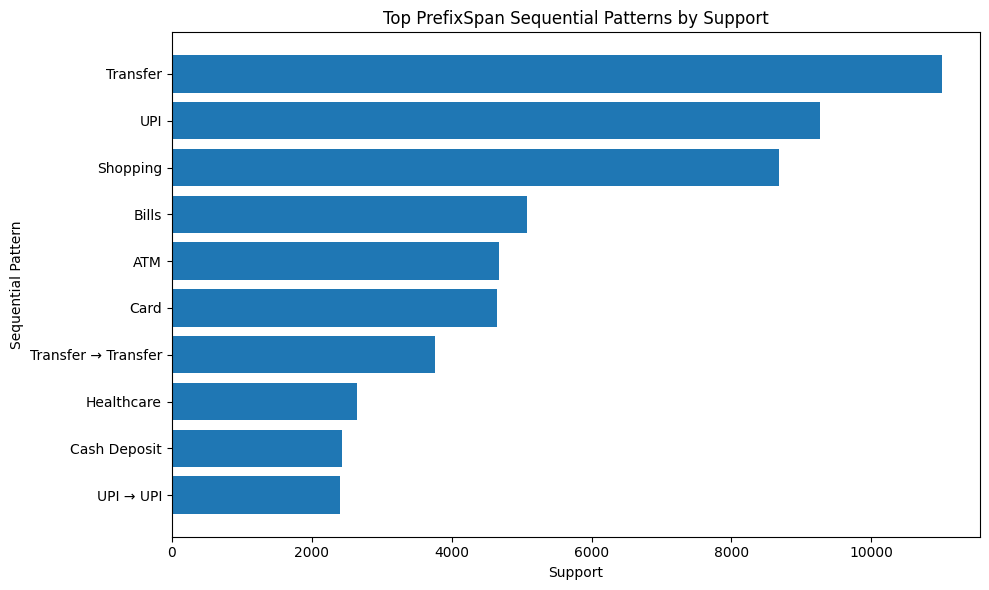

In [ ]:
# Cell 40 — Top PrefixSpan Patterns

import matplotlib.pyplot as plt

top_n = 10

plot_df = prefixspan_results.head(top_n).copy()
plot_df = plot_df.sort_values("support")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["pattern"],
    plot_df["support"]
)

plt.xlabel("Support")
plt.ylabel("Sequential Pattern")
plt.title("Top PrefixSpan Sequential Patterns by Support")

plt.tight_layout()
plt.show()

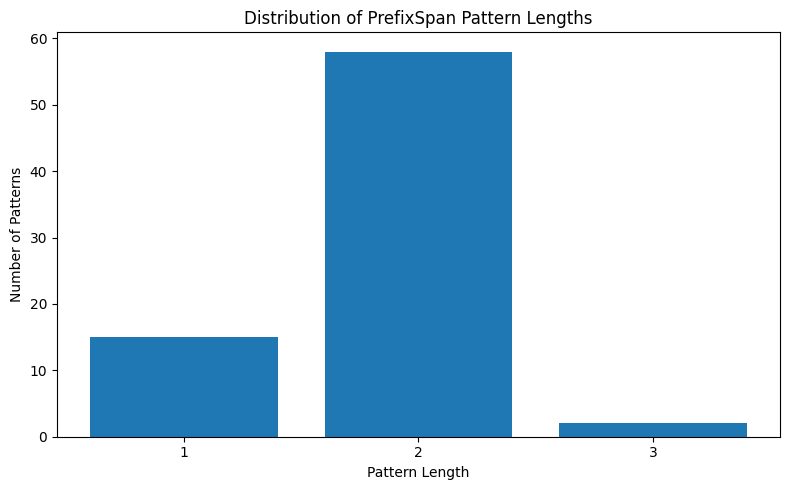

In [ ]:
# Cell 41 — PrefixSpan Pattern Length Distribution

length_counts = (
    prefixspan_results["length"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    length_counts.index.astype(str),
    length_counts.values
)

plt.xlabel("Pattern Length")
plt.ylabel("Number of Patterns")
plt.title("Distribution of PrefixSpan Pattern Lengths")

plt.tight_layout()
plt.show()

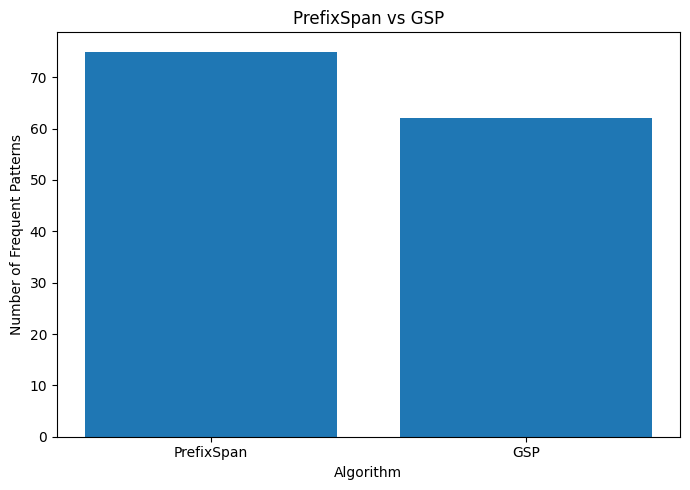

In [ ]:
# Cell 42 — PrefixSpan vs GSP

algorithms = ["PrefixSpan", "GSP"]

pattern_counts = [
    len(prefixspan_results),
    len(gsp_results_df)
]

plt.figure(figsize=(7, 5))

plt.bar(
    algorithms,
    pattern_counts
)

plt.xlabel("Algorithm")
plt.ylabel("Number of Frequent Patterns")
plt.title("PrefixSpan vs GSP")

plt.tight_layout()
plt.show()

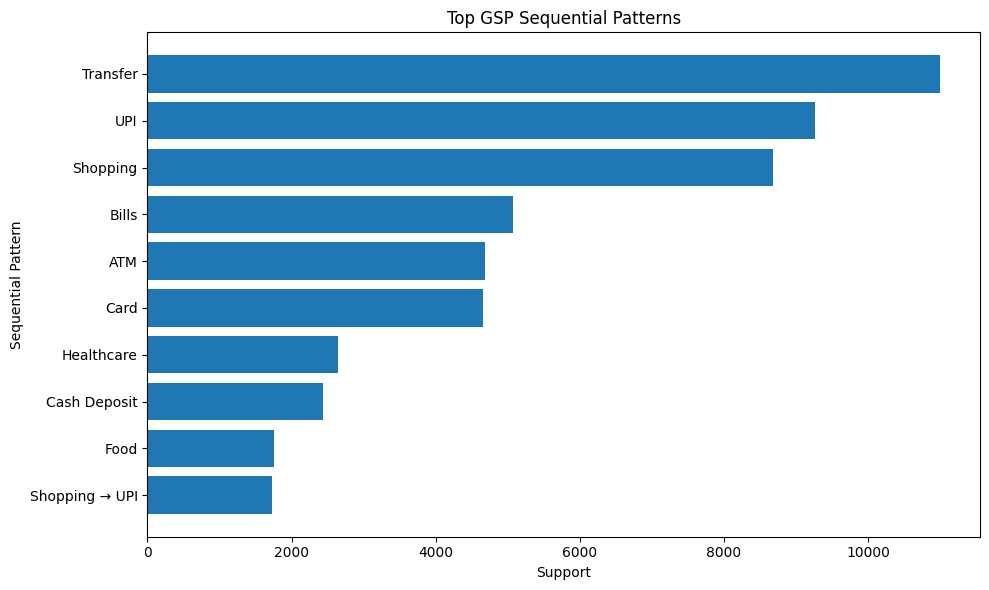

In [ ]:
# Cell 43 — Top GSP Patterns

top_gsp = (
    gsp_results_df
    .head(10)
    .sort_values("support")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_gsp["pattern"],
    top_gsp["support"]
)

plt.xlabel("Support")
plt.ylabel("Sequential Pattern")
plt.title("Top GSP Sequential Patterns")

plt.tight_layout()
plt.show()

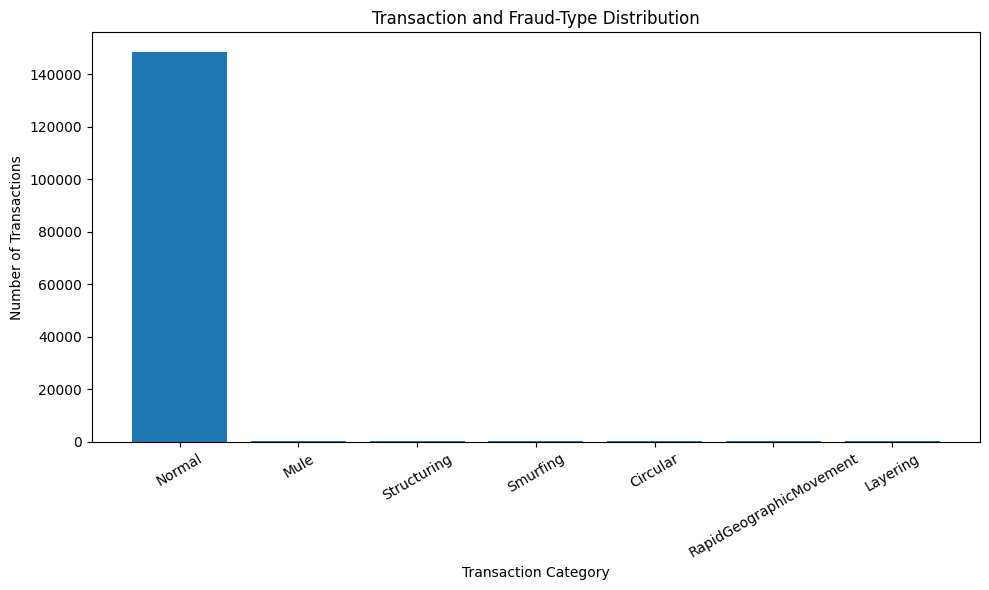

In [ ]:
# Cell 44 — Fraud Distribution

fraud_counts = (
    df["fraud_type"]
    .value_counts()
)

plt.figure(figsize=(10, 6))

plt.bar(
    fraud_counts.index,
    fraud_counts.values
)

plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")
plt.title("Transaction and Fraud-Type Distribution")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
plt.savefig(
    "/content/drive/MyDrive/AML_Project/outputs/prefixspan_top_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
# Cell 42 — Fraud Pattern Coverage

coverage = (
    prefixspan_fraud_matches
    .groupby("fraud_type")
    .agg(
        matched_patterns=("pattern_id","nunique"),
        total_matches=("pattern_id","count")
    )
    .reset_index()
)

coverage["Injected Patterns"] = 50

coverage["Coverage (%)"] = (
    coverage["matched_patterns"] /
    coverage["Injected Patterns"]
)*100

coverage = coverage[
    [
        "fraud_type",
        "Injected Patterns",
        "matched_patterns",
        "Coverage (%)"
    ]
]

coverage

,fraud_type,Injected Patterns,matched_patterns,Coverage (%)
0,Circular,50,50,100.0
1,Layering,50,50,100.0
2,Mule,50,50,100.0
3,RapidGeographicMovement,50,50,100.0
4,Smurfing,50,50,100.0
5,Structuring,50,50,100.0


In [ ]:
# Cell 43 — Save Outputs

output_path = "/content/drive/MyDrive/AML_Project/outputs/"

prefixspan_results.to_csv(
    output_path + "prefixspan_results.csv",
    index=False
)

rich_prefixspan_results.to_csv(
    output_path + "rich_prefixspan_results.csv",
    index=False
)

gsp_results_df.to_csv(
    output_path + "gsp_results.csv",
    index=False
)

coverage.to_csv(
    output_path + "fraud_pattern_coverage.csv",
    index=False
)

comparison.to_csv(
    output_path + "algorithm_comparison.csv",
    index=False
)

print("Sequential mining results saved successfully!")

Sequential mining results saved successfully!
